In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import PowerTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score,mean_absolute_error, mean_squared_error
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor

In [2]:
df=pd.read_csv('C:\\Users\\NOTHING\\Pictures\\ValueLens AI\\data\\processed\\customer_features.csv')

In [3]:
df

,Customer ID,Recency,Frequency,Monetary,Tenure,AvgOrderValue,ProductDiversity,WeekendRatio,future_6m_clv
0,12346,134,8,77556.46,534,9694.5575,27,0.000000,0.00
1,12347,55,4,2434.96,213,608.7400,90,0.322581,2486.57
2,12348,57,4,1709.40,247,427.3500,25,0.000000,310.00
3,12349,216,3,2671.14,398,890.3800,90,0.000000,1757.55
4,12350,119,1,334.40,119,334.4000,17,0.000000,0.00
...,...,...,...,...,...,...,...,...,...
4930,18283,9,10,1134.89,467,113.4890,240,0.225513,1530.01
4931,18284,240,1,461.68,240,461.6800,28,0.000000,0.00
4932,18285,469,1,427.00,469,427.0000,12,0.000000,0.00
4933,18286,285,2,1296.43,532,648.2150,67,0.000000,0.00


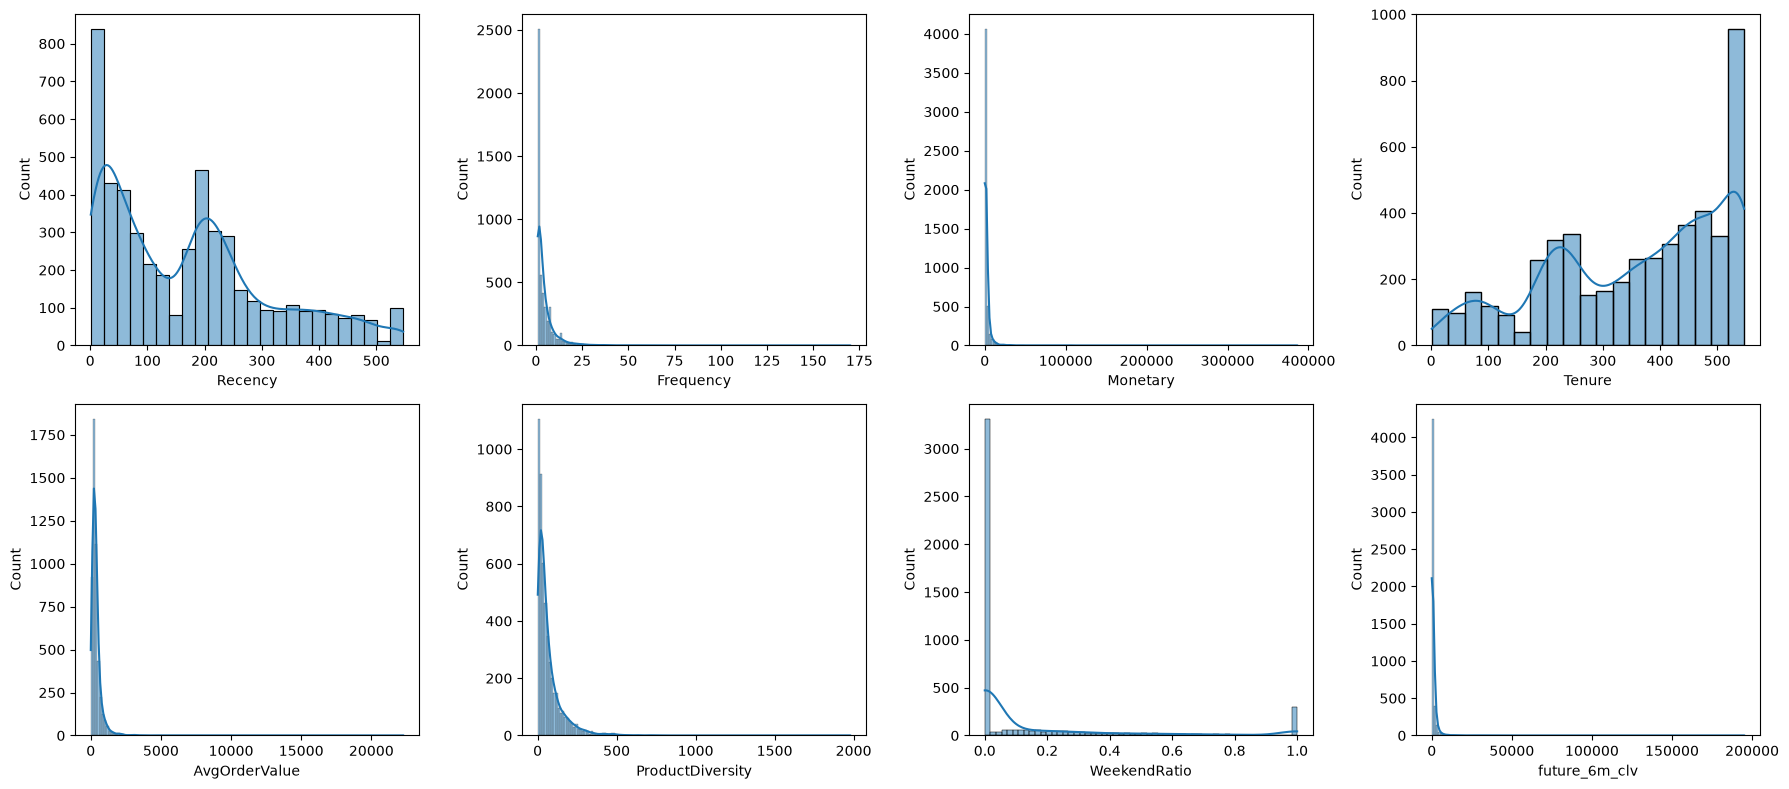

In [4]:
fig, ax = plt.subplots(2, 4, figsize=(18, 8))

sns.histplot(df['Recency'], kde=True, ax=ax[0,0])
sns.histplot(df['Frequency'], kde=True, ax=ax[0,1])
sns.histplot(df['Monetary'], kde=True, ax=ax[0,2])
sns.histplot(df['Tenure'], kde=True, ax=ax[0,3])

sns.histplot(df['AvgOrderValue'], kde=True, ax=ax[1,0])
sns.histplot(df['ProductDiversity'], kde=True, ax=ax[1,1])
sns.histplot(df['WeekendRatio'], kde=True, ax=ax[1,2])
sns.histplot(df['future_6m_clv'], kde=True, ax=ax[1,3])

plt.tight_layout()
plt.show()

In [5]:
X = df.drop(columns=['future_6m_clv','Customer ID'])
y = df.iloc[:,-1]

In [6]:
X_train,X_test,y_train,y_test = train_test_split(X,y, test_size=0.2,random_state=42)

In [7]:
y_train_log=np.log1p(y_train)
y_test_log=np.log1p(y_test)

In [8]:
pt=PowerTransformer()
X_train_trf=pt.fit_transform(X_train)
X_test_trf=pt.transform(X_test)

In [9]:
lr = LinearRegression()
lr.fit(X_train_trf,y_train_log)
y_pred_log=lr.predict(X_test_trf)
r2_score(y_test_log,y_pred_log)

0.38556535183027485

In [10]:
np.mean(cross_val_score(lr,X_train_trf,y_train_log,cv=10,scoring='r2',n_jobs=-1))

np.float64(0.36212631668727535)

In [11]:
mean_absolute_error(y_test_log,y_pred_log)

2.201003553577676

In [12]:
np.sqrt(mean_squared_error(y_test_log,y_pred_log))

np.float64(2.624265840543935)

In [13]:
y_pred=np.expm1(y_pred_log)
y_test=np.expm1(y_test_log)

In [14]:
print(r2_score(y_test,y_pred))
print(mean_absolute_error(y_test,y_pred))
print(np.sqrt(mean_squared_error(y_test,y_pred)))

0.3532837103645028
560.7264837021451
1677.3375807760544


In [28]:
lr.coef_

array([-0.80710697,  0.31817683,  1.34228323, -0.19958617, -0.31722631,
        0.17462386, -0.02613223])

In [15]:
rf = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train,y_train_log)
y_pred_log=rf.predict(X_test)

y_pred=np.expm1(y_pred_log)

In [16]:
print(r2_score(y_test,y_pred))
print(mean_absolute_error(y_test,y_pred))
print(np.sqrt(mean_squared_error(y_test,y_pred)))

0.5191572583929824
522.7275148634362
1446.3223909981432


In [17]:
scores = cross_val_score(
    rf,
    X,
    np.log1p(y),
    cv=10,
    scoring="r2",
    n_jobs=-1)

print("CV R²:", scores.mean())

CV R²: 0.3391988958592263


In [25]:
rf.feature_importances_

array([0.19843169, 0.04658519, 0.39070296, 0.1067006 , 0.11557293,
       0.10933802, 0.03266861])

In [18]:
xgb = XGBRegressor(
    n_estimators=200,
    learning_rate=0.05,
    random_state=42
)

xgb.fit(X_train,y_train_log)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [19]:
y_pred_log=xgb.predict(X_test)

In [20]:
y_pred=np.expm1(y_pred_log)

In [21]:
print(r2_score(y_test,y_pred))
print(mean_absolute_error(y_test,y_pred))
print(np.sqrt(mean_squared_error(y_test,y_pred)))

0.5500353091866291
497.76037052747813
1399.1130104939455


In [23]:
scores = cross_val_score(
    xgb,
    X,
    np.log1p(y),
    cv=10,
    scoring="r2",
    n_jobs=-1)

print("CV R²:", scores.mean())

CV R²: 0.3661932683500675


In [24]:
xgb.feature_importances_

array([0.14504737, 0.1129686 , 0.43438065, 0.08474366, 0.07213442,
       0.08392914, 0.06679616], dtype=float32)

## Benchmarking against BG/NBD + Gamma-Gamma

In [74]:
df1 = pd.read_csv('df_features.csv')

In [75]:
train_customer_ids = df.loc[y_train.index, 'Customer ID']
test_customer_ids = df.loc[y_test.index, 'Customer ID']

In [82]:
train_customer_ids

3172    16184
2231    15052
1115    13734
4130    17320
1945    14717
        ...  
4426    17677
466     12944
3092    16087
3772    16898
860     13432
Name: Customer ID, Length: 3948, dtype: int64

In [76]:
df1_train = df1[df1['Customer ID'].isin(train_customer_ids)]
df1_test = df1[df1['Customer ID'].isin(test_customer_ids)]

In [77]:
print(df1_train['Customer ID'].nunique())
print(df1_test['Customer ID'].nunique())

3948
987


In [87]:
from lifetimes.utils import summary_data_from_transaction_data

summary_train = summary_data_from_transaction_data(
    df1_train,
    customer_id_col='Customer ID',
    datetime_col='Purchased_Date',
    monetary_value_col='Revenue',
    observation_period_end='2011-06-01'
)

print(summary_train.head())
print(summary_train.shape)

             frequency  recency      T  monetary_value
Customer ID                                           
12346.0            7.0    400.0  534.0    11066.637143
12347.0            3.0    158.0  213.0      607.810000
12348.0            3.0    190.0  247.0      495.746667
12349.0            2.0    182.0  398.0      801.310000
12350.0            0.0      0.0  119.0        0.000000
(3948, 4)


In [79]:
from lifetimes import BetaGeoFitter, GammaGammaFitter

bgf = BetaGeoFitter(penalizer_coef=0.001)
bgf.fit(summary_train['frequency'], summary_train['recency'], summary_train['T'])

repeat_customers_train = summary_train[summary_train['frequency'] > 0]
ggf = GammaGammaFitter(penalizer_coef=0.001)
ggf.fit(repeat_customers_train['frequency'], repeat_customers_train['monetary_value'])

<lifetimes.GammaGammaFitter: fitted with 2648 subjects, p: 11.79, q: 0.88, v: 11.72>

In [80]:
summary_test = summary_data_from_transaction_data(
    df1_test,
    customer_id_col='Customer ID',
    datetime_col='Purchased_Date',
    monetary_value_col='Revenue',
    observation_period_end='2011-06-01'
)

summary_test['predicted_clv'] = ggf.customer_lifetime_value(
    bgf,
    summary_test['frequency'],
    summary_test['recency'],
    summary_test['T'],
    summary_test['monetary_value'],
    time=6,
    freq='D',
    discount_rate=0.0
)

In [81]:
test_customer_ids_float = test_customer_ids.astype(float)
test_comparison = summary_test.reindex(test_customer_ids_float)['predicted_clv']

from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

print(r2_score(y_test, test_comparison))
print(mean_absolute_error(y_test, test_comparison))
print(np.sqrt(mean_squared_error(y_test, test_comparison)))

0.44603374860620515
646.3036772133447
1552.4057087921485


In [89]:
import joblib
joblib.dump(xgb,'C:\\Users\\NOTHING\\Pictures\\ValueLens AI\\models\\clv_model.pkl')

['C:\\Users\\NOTHING\\Pictures\\ValueLens AI\\models\\clv_model.pkl']